### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("..")

from query_history import query_history
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic
from sklearn.model_selection import LeaveOneOut, cross_val_score

### Data loading + appending with results from previous query

In [2]:
functions = {}

for i in range(1, 9):
    # Loading original data
    X = np.load(f"../initial_data/function_{i}/initial_inputs.npy")
    y = np.load(f"../initial_data/function_{i}/initial_outputs.npy")

    # Appending queries collected so far
    for query_X, query_y in query_history[i]:
        X = np.vstack([X, query_X])
        y = np.append(y, query_y)

    functions[i] = {
        "X": X,
        "y": y
    }

In [3]:
for i in range(1, 9):
    print(f"Function {i}: X = {functions[i]['X'].shape}, y = {functions[i]['y'].shape}")

Function 1: X = (11, 2), y = (11,)
Function 2: X = (11, 2), y = (11,)
Function 3: X = (16, 3), y = (16,)
Function 4: X = (31, 4), y = (31,)
Function 5: X = (21, 4), y = (21,)
Function 6: X = (21, 5), y = (21,)
Function 7: X = (31, 6), y = (31,)
Function 8: X = (41, 8), y = (41,)


### Reusable functions

In [4]:
def check_result(i):
    X, y = functions[i]["X"], functions[i]["y"]
    best = np.argmax(y)

    print(f"Function {i}")
    print(f"Latest: X={X[-1]}, y={y[-1]}")
    print(f"Best:   X={X[best]}, y={y[best]}")

In [5]:
def plot_2d(i, y=None):
    X = functions[i]["X"]
    y = functions[i]["y"] if y is None else y

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=80)
    plt.colorbar(label="Output")

    # Last week's query
    plt.scatter(X[-1, 0], X[-1, 1],
                marker="*", s=250, edgecolors="red",
                facecolors="none", linewidths=2,
                label="Last query")

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}")
    plt.legend()
    plt.show()

In [6]:
kernels = {
    "RBF": RBF(0.1),
    "Matern": Matern(0.1, nu=2.5),
    "RQ": RationalQuadratic(length_scale=0.1, alpha=1.0)
}

length_scales = [0.05, 0.1, 0.2, 0.5]

def validate_kernels(i):
    X, y = functions[i]["X"], functions[i]["y"]
    results = {}

    for ls in length_scales:
        kernels = {
            "RBF": RBF(ls),
            "Matern": Matern(ls, nu=2.5),
            "RQ": RationalQuadratic(length_scale=ls, alpha=1.0)
        }

        for name, kernel in kernels.items():
            gp = GaussianProcessRegressor(
                kernel=kernel,
                normalize_y=True,
                optimizer=None
            )

            mae = -cross_val_score(
                gp, X, y,
                cv=LeaveOneOut(),
                scoring="neg_mean_absolute_error"
            ).mean()

            results[(name, ls)] = mae

    return sorted(results.items(), key=lambda x: x[1])

In [7]:
def fit_gp(i, kernel, transform=False):
    X, y = functions[i]["X"], functions[i]["y"]

    if transform:
        y = scale_scores(y)

    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        optimizer=None
    )

    gp.fit(X, y)
    return gp

In [17]:
def plot_gp_2d(i, gp, suggestions=None):
    X = functions[i]["X"]

    grid = np.linspace(0, 1, 100)
    x1, x2 = np.meshgrid(grid, grid)
    X_grid = np.c_[x1.ravel(), x2.ravel()]

    mean = gp.predict(X_grid)

    plt.contourf(x1, x2, mean.reshape(x1.shape), levels=30)
    plt.colorbar(label="Predicted output")
    plt.scatter(X[:, 0], X[:, 1], c="white", edgecolors="black")

    if suggestions:
        for name, point in suggestions.items():
            plt.scatter(*point, marker="X", s=120, label=name)

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}: GP predicted mean")
    plt.legend()
    plt.show()

In [9]:
def acquisitions(gp, X_candidates, best_y, beta=1.96):
    mean, std = gp.predict(X_candidates, return_std=True)

    # UCB
    ucb = mean + beta * std

    # EI + PI
    improvement = mean - best_y
    z = improvement / (std + 1e-9)

    ei = improvement * norm.cdf(z) + std * norm.pdf(z)
    pi = norm.cdf(z)

    return {
        "UCB": X_candidates[np.argmax(ucb)],
        "EI":  X_candidates[np.argmax(ei)],
        "PI":  X_candidates[np.argmax(pi)]
    }

In [58]:
def check_uncertainty(gp, suggestions):
    for name, point in suggestions.items():
        mean, std = gp.predict(point.reshape(1, -1), return_std=True)

        print(
            f"{name}: mean={mean[0]:.4f}, "
            f"uncertainty={std[0]:.4f}"
        )

In [62]:
def plot_scores(i):
    y = functions[i]["y"]
    positions = np.arange(len(y))
    best = np.argmax(y)

    plt.figure(figsize=(10, 5))
    plt.scatter(positions, y, s=70)

    # Label points with array position
    for pos, score in zip(positions, y):
        plt.annotate(str(pos), (pos, score),
                     xytext=(5, 5),
                     textcoords="offset points")

    # Last week's query
    plt.scatter(positions[-1], y[-1],
                marker="*", s=250,
                facecolors="none", edgecolors="red",
                linewidths=2, label="Last week's query")

    # Best observation
    plt.scatter(best, y[best],
                marker="X", s=200,
                label="Best score")

    plt.xlabel("Array position")
    plt.ylabel("Observed score")
    plt.title(f"Function {i}: Observed Scores")
    plt.legend()
    plt.show()

### Function 1

using transformations to make sense of the data

In [10]:
from sklearn.preprocessing import QuantileTransformer

def scale_scores(y):
    qt = QuantileTransformer(
        n_quantiles=len(y),
        output_distribution="uniform"
    )
    return qt.fit_transform(y.reshape(-1, 1)).ravel()

[0.5 0.8 1.  0.4 0.  0.2 0.3 0.9 0.5 0.7 0.1]


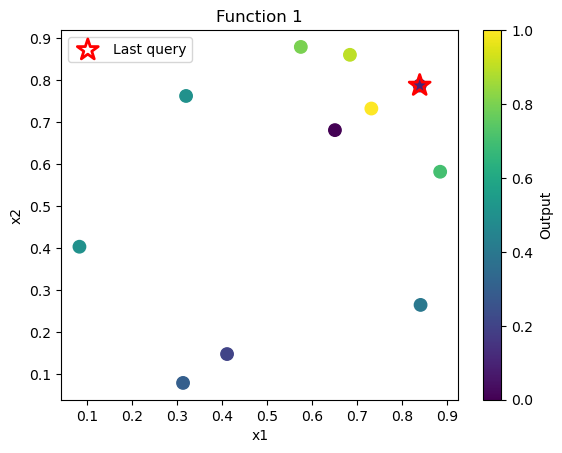

In [11]:
y_scaled = scale_scores(functions[1]["y"])

print(y_scaled)
plot_2d(1, y_scaled)

above i wanted to get a clearer visual picture of the promising region which seems to be approx (0.7, 0.8) - lets see if our new strategy agrees with this for the new query

In [12]:
validate_kernels(1)

[(('Matern', 0.05), np.float64(0.0006805348479151934)),
 (('RBF', 0.05), np.float64(0.0006846801600559985)),
 (('RQ', 0.05), np.float64(0.0007096467827269751)),
 (('Matern', 0.1), np.float64(0.0007326717601635349)),
 (('RQ', 0.1), np.float64(0.0008007521874227229)),
 (('RBF', 0.1), np.float64(0.0008387942257437522)),
 (('Matern', 0.2), np.float64(0.0010189123427982137)),
 (('RQ', 0.2), np.float64(0.0011625388955434923)),
 (('RBF', 0.2), np.float64(0.0013996939691102216)),
 (('Matern', 0.5), np.float64(0.001580467168858373)),
 (('RQ', 0.5), np.float64(0.0020516357148846346)),
 (('RBF', 0.5), np.float64(0.0036196004026023566))]

LOOCV showed that all three kernels performed best with a short length scale of 0.05, suggesting that F1 may vary substantially over small changes in input. Matérn 5/2 achieved the lowest MAE, although its performance was very close to RBF at the same length scale.

In [13]:
best_kernel = Matern(length_scale=0.05, nu=2.5)

gp_f1_scaled = fit_gp(
    1,
    best_kernel,
    transform=True
)

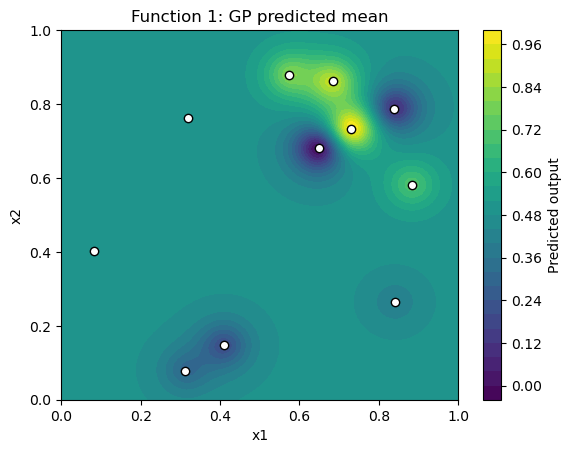

In [14]:
plot_gp_2d(1, gp_f1_scaled)

#### ucb, ei, pi

In [15]:
rng = np.random.RandomState(42)
X_candidates = rng.rand(10000, 2)

In [16]:
suggestions = acquisitions(
    gp_f1_scaled,
    X_candidates,
    best_y=1.0
)

suggestions

{'UCB': array([0.72192397, 0.77351919]),
 'EI': array([0.72870925, 0.76121152]),
 'PI': array([0.7362376 , 0.73221756])}

all three acquisition functions suggest querying a similar region. this also aligns with my own observations, as F1 appears highly sensitive to small changes in the inputs, so exploiting the promising region around the current best point seems appropriate.

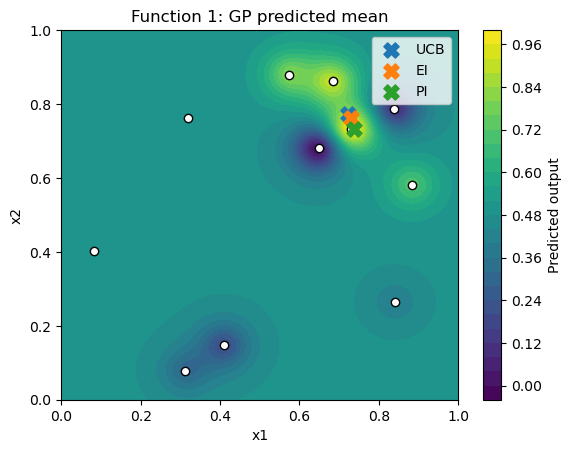

In [18]:
plot_gp_2d(1, gp_f1_scaled, suggestions)

I am selecting the EI suggestion as it exploits the promising region around the current best point while still testing a nearby unexplored location.

#### chosen query for F1

`0.728709-0.761212`

### Function 2

Function 2
Latest: X=[0.799891 0.925328], y=0.03788056227520092
Best:   X=[0.70263656 0.9265642 ], y=0.6112052157614438


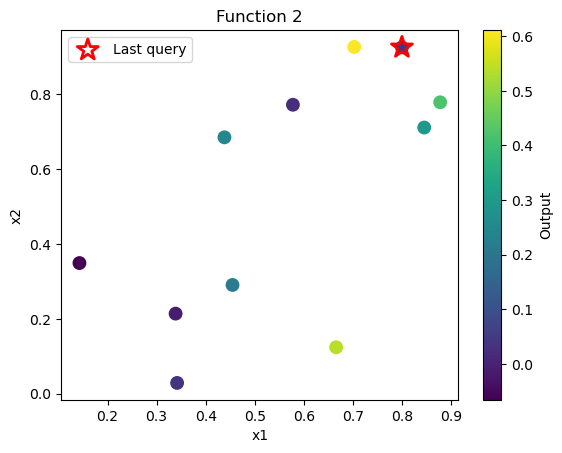

In [19]:
check_result(2)
plot_2d(2)

In [20]:
validate_kernels(2)

[(('RBF', 0.05), np.float64(0.20737600430302125)),
 (('Matern', 0.05), np.float64(0.20938607005730497)),
 (('RQ', 0.05), np.float64(0.2189016721919299)),
 (('Matern', 0.1), np.float64(0.244772802084844)),
 (('RQ', 0.1), np.float64(0.25704889550509086)),
 (('RBF', 0.1), np.float64(0.2656391445711987)),
 (('Matern', 0.2), np.float64(0.3069147146195982)),
 (('RQ', 0.2), np.float64(0.3243248422797824)),
 (('Matern', 0.5), np.float64(0.3489653157336504)),
 (('RBF', 0.2), np.float64(0.3704893285629593)),
 (('RQ', 0.5), np.float64(0.41818696198796224)),
 (('RBF', 0.5), np.float64(0.7522263030091537))]

In [21]:
best_kernel_f2 = RBF(length_scale=0.05)
gp_f2 = fit_gp(2, best_kernel_f2)

In [22]:
rng = np.random.RandomState(42)
X_candidates = rng.rand(10000, 2)

for beta in [1, 1.96, 3, 5]:
    result = acquisitions(
        gp_f2,
        X_candidates,
        best_y=functions[2]["y"].max(),
        beta=beta
    )
    print(beta, result["UCB"])

1 [0.67532353 0.93249587]
1.96 [0.65866135 0.93155491]
3 [0.65365648 0.95622117]
5 [0.64686022 0.97029373]


In [23]:
suggestions_f2 = acquisitions(
    gp_f2,
    X_candidates,
    best_y=functions[2]["y"].max(),
    beta=3
)

suggestions_f2

{'UCB': array([0.65365648, 0.95622117]),
 'EI': array([0.67532353, 0.93249587]),
 'PI': array([0.69823299, 0.92618892])}

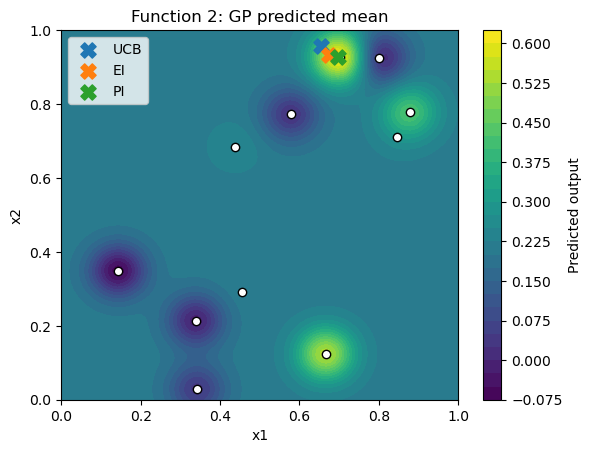

In [24]:
plot_gp_2d(2, gp_f2, suggestions_f2)

Looking back at my initial hypothesis from last week, I still believe that the region around `x1 = 0.69-0.71` is particularly promising. So, I want to take a more exploratory approach than the GP suggestions, which appear to be exploitative around the current best.

#### chosen query for F2

`0.69-0.5`

### Function 3

In [25]:
check_result(3)
validate_kernels(3)

Function 3
Latest: X=[0.491183 0.678883 0.145856], y=-0.09952109690023639
Best:   X=[0.49258141 0.61159319 0.34017639], y=-0.034835313350078584


[(('RQ', 0.05), np.float64(0.04618287212134109)),
 (('Matern', 0.05), np.float64(0.04649202771144283)),
 (('RBF', 0.05), np.float64(0.046720651942249974)),
 (('Matern', 0.1), np.float64(0.047070853984258414)),
 (('RBF', 0.1), np.float64(0.047269372351810154)),
 (('RQ', 0.1), np.float64(0.049625812326912204)),
 (('Matern', 0.2), np.float64(0.05281381535140505)),
 (('RBF', 0.2), np.float64(0.05719524070861856)),
 (('RQ', 0.2), np.float64(0.05773957578206314)),
 (('Matern', 0.5), np.float64(0.06858896909661048)),
 (('RQ', 0.5), np.float64(0.06875914022126248)),
 (('RBF', 0.5), np.float64(0.08059369623533787))]

In [26]:
best_kernel_f3 = RationalQuadratic(
    length_scale=0.05,
    alpha=1.0
)

gp_f3 = fit_gp(3, best_kernel_f3)

In [27]:
rng = np.random.RandomState(42)
X_candidates_f3 = rng.rand(20000, 3)

suggestions_f3 = acquisitions(
    gp_f3,
    X_candidates_f3,
    best_y=functions[3]["y"].max(),
    beta=1.96
)

suggestions_f3

{'UCB': array([0.231979  , 0.23963812, 0.42995773]),
 'EI': array([0.18113501, 0.27089522, 0.41896845]),
 'PI': array([0.49636625, 0.59684285, 0.33424389])}

In [48]:
def plot_3d(i, suggestions=None):
    X, y = functions[i]["X"], functions[i]["y"]

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    p = ax.scatter(X[:, 0], X[:, 1], X[:, 2],
                   c=y, cmap="viridis", s=70)

    # Last week's query
    ax.scatter(*X[-1], marker="*", s=300,
               edgecolors="red", facecolors="none",
               linewidths=2, label="Last week's query")

    if suggestions:
        for name, point in suggestions.items():
            ax.scatter(*point, marker="X", s=150, label=name)

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("x3")
    ax.set_title(f"Function {i}")
    ax.legend()
    plt.colorbar(p, label="Output")
    plt.show()

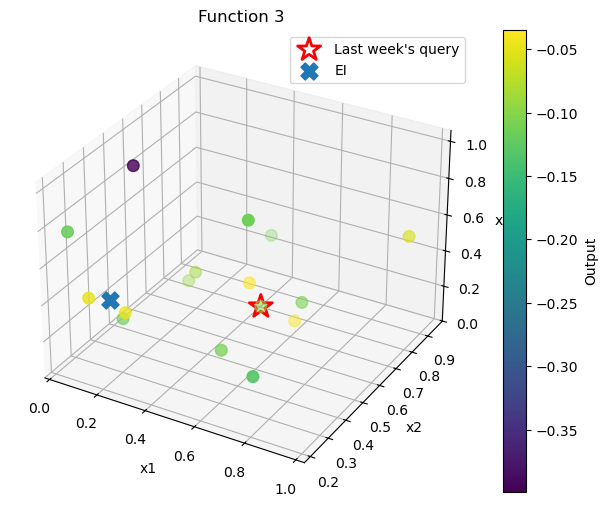

In [54]:
plot_3d(3, {
    "EI": suggestions_f3["EI"]
})

In [52]:
for name, point in suggestions_f3.items():
    mean, std = gp_f3.predict(point.reshape(1, -1), return_std=True)
    print(name, "mean:", round(mean[0], 4),
          "uncertainty:", round(std[0], 4))

UCB mean: -0.0756 uncertainty: 0.0742
EI mean: -0.0654 uncertainty: 0.0683
PI mean: -0.0385 uncertainty: 0.0256


After considering the previous query and comparing the acquisition functions, I decided to use EI for F3. Last week's query was already relatively exploratory and did not improve the current best, so I did not want to pursue an even more uncertain UCB suggestion. However, PI was very close to the existing best point and therefore offered little exploration. EI provides a compromise by exploring a different region while still being supported by relatively strong existing observations.

#### chosen query for F3

`0.181135-0.270895-0.418968`

### Function 4

In [55]:
check_result(4)
validate_kernels(4)

Function 4
Latest: X=[0.517542 0.395784 0.479356 0.197097], y=-5.1373413616802495
Best:   X=[0.57776561 0.42877174 0.42582587 0.24900741], y=-4.025542281908162


[(('RBF', 0.5), np.float64(1.5767689209705935)),
 (('RQ', 0.5), np.float64(1.6563346205904101)),
 (('Matern', 0.5), np.float64(2.1210494470107784)),
 (('RQ', 0.2), np.float64(3.0052362270128166)),
 (('RBF', 0.2), np.float64(3.48454684089236)),
 (('Matern', 0.2), np.float64(3.5089430645026085)),
 (('RQ', 0.1), np.float64(3.8680453358653413)),
 (('RBF', 0.1), np.float64(4.57837501125815)),
 (('Matern', 0.1), np.float64(4.70568274573134)),
 (('RQ', 0.05), np.float64(4.946534807823547)),
 (('Matern', 0.05), np.float64(5.684324958287289)),
 (('RBF', 0.05), np.float64(5.706604465757145))]

unlike F2/F3, the evidence suggests F4 has a considerably smoother landscape since all kernels perform considerably better with length scale 0.5

In [56]:
best_kernel_f4 = RBF(length_scale=0.5)
gp_f4 = fit_gp(4, best_kernel_f4)

In [57]:
rng = np.random.RandomState(42)
X_candidates = rng.rand(20000, 4)

suggestions_f4 = acquisitions(
    gp_f4,
    X_candidates,
    best_y=functions[4]["y"].max(),
    beta=1.96
)

suggestions_f4

{'UCB': array([0.40447668, 0.41325432, 0.30310769, 0.43435853]),
 'EI': array([0.50797812, 0.51621189, 0.32476775, 0.42409928]),
 'PI': array([0.59603016, 0.46038618, 0.36440987, 0.35300475])}

In [59]:
check_uncertainty(gp_f4, suggestions_f4)

UCB: mean=-1.0014, uncertainty=0.9903
EI: mean=-0.9095, uncertainty=0.6655
PI: mean=-2.2841, uncertainty=0.2835


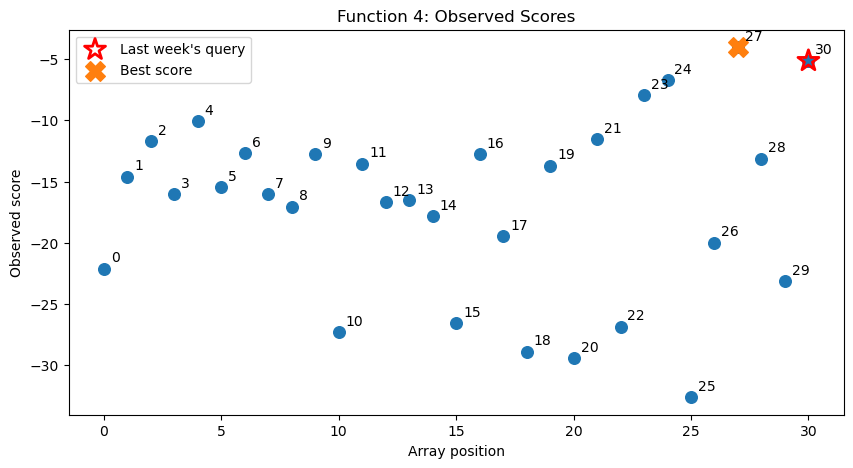

In [63]:
plot_scores(4)

based on this plot, exploiting the `0.577766-0.428772-0.425826-0.249007` region seems to be promising. now i will check to see if the GP agrees.

In [64]:
suggestions_f4 = acquisitions(
    gp_f4,
    X_candidates,
    best_y=functions[4]["y"].max(),
    beta=1.96
)

print(suggestions_f4)
check_uncertainty(gp_f4, suggestions_f4)

{'UCB': array([0.40447668, 0.41325432, 0.30310769, 0.43435853]), 'EI': array([0.50797812, 0.51621189, 0.32476775, 0.42409928]), 'PI': array([0.59603016, 0.46038618, 0.36440987, 0.35300475])}
UCB: mean=-1.0014, uncertainty=0.9903
EI: mean=-0.9095, uncertainty=0.6655
PI: mean=-2.2841, uncertainty=0.2835


For F4, I chose to take a more exploitative approach. The previous query produced the second-best observed result, providing further evidence that the region surrounding the current best is promising. PI suggested a nearby point with substantially lower uncertainty than EI and UCB, while still exploring a new combination of inputs. I therefore chose the PI suggestion to refine this promising region rather than taking a larger exploratory step.

#### chosen query for F4

`0.59603016-0.46038618-0.36440987-0.35300475`